# Laboratorium 3: Od tokenów do reprezentacji wektorowych

W tym laboratorium porównamy rzadkie i gęste reprezentacje wektorowe oraz sprawdzimy, jak zachowują się w zadaniach opartych na podobieństwie tekstów.

Porównujemy:

- TF-IDF,
- `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,
- `intfloat/multilingual-e5-small`.

Główne pytanie laboratorium:

**Czy bliskość dwóch tekstów w przestrzeni wektorowej odpowiada podobieństwu, którego potrzebujemy w konkretnym zadaniu NLP?**


## Po tych zajęciach student potrafi

- wyjaśnić różnicę między rzadką i gęstą reprezentacją wektorową;
- obliczyć i zinterpretować podobieństwo cosinusowe;
- wygenerować reprezentacje tekstu za pomocą modelu embeddingowego;
- zaimplementować wyszukiwanie najbliższych sąsiadów;
- ocenić jakość lokalnego sąsiedztwa;
- zbudować prosty benchmark wyszukiwania;
- zastosować PCA do analizy przestrzeni reprezentacji;
- rozpoznać przypadki, w których wysokie podobieństwo wektorowe nie odpowiada wymaganiom zadania;
- porównać jakość reprezentacji z jej kosztem obliczeniowym;
- uzasadnić wybór reprezentacji dla konkretnego zastosowania.


## Dane

Pracujemy na zbiorze PolEmo 2.0 wykorzystywanym w poprzednich laboratoriach.

Jeżeli istnieje plik:

```text
artifacts/polemo2_clean.parquet
```

należy użyć tej wersji danych. Jeśli pliku nie ma, proszę wrócić do Lab 1 i go przygotować.

W tym laboratorium nie używamy zbioru testowego do wyboru reprezentacji ani do strojenia eksperymentów.


## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow sentence-transformers
```

Kod startowy obejmuje wyłącznie importy, stałe i wczytanie danych. Implementacja eksperymentów należy do Państwa.


In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

from sentence_transformers import SentenceTransformer

RANDOM_STATE = 42
SAMPLE_SIZE = 1000

ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_A = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_B = "intfloat/multilingual-e5-small"

pd.set_option("display.max_colwidth", 180)


W1026 22:50:47.156000 4371 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)  # tylko train, bez validation i test
print(train_df.shape)
display(train_df.head())

(5782, 18)


,text,target,split,n_chars,n_words,n_words_split,n_lines,has_url,has_email,has_punct_burst,has_newline,is_very_short,uppercase_ratio,high_uppercase,text_raw,text_norm,random_split,dup_in_split
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,681,105,126,1,False,False,False,False,False,0.028037,False,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...","super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",train,False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,663,97,107,1,False,False,False,False,False,0.012844,False,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,train,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,304,41,50,1,False,False,False,False,False,0.016260,False,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...","lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",train,False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,917,127,156,1,False,False,False,False,False,0.009550,False,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",test,False
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,570,89,109,1,False,False,False,False,False,0.049774,False,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...","pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",train,False


# Zadanie 1: TF-IDF i podobieństwo cosinusowe

Proszę rozpocząć od tekstów:

```text
A = "hotel czysty wygodny"
B = "hotel bardzo czysty"
C = "samochód szybki sportowy"
```

Proszę zaimplementować:

1. reprezentację TF-IDF;
2. tabelę wartości TF-IDF;
3. macierz podobieństwa cosinusowego;
4. wskazanie najbardziej podobnej pary.

Następnie proszę powtórzyć eksperyment dla:

```text
A = "Hotel był bardzo dobry."
B = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
C = "Hotel był bardzo zły."
```

Przed uruchomieniem kodu proszę zapisać, która para powinna być najbardziej podobna według TF-IDF, a która według człowieka.

**Hipoteza:** dla pierwszego zestawu zarówno człowiek, jak i TF-IDF wskażą parę A–B (wspólne słowa „hotel” i „czysty”). Dla drugiego zestawu człowiek wskazałby A–B, bo B jest parafrazą A, natomiast zakładam, że TF-IDF uzna za najbardziej podobne A–C, bo mają wspólne słowa „hotel był bardzo”.

In [3]:
# Proszę zaimplementować rozwiązanie zadania 1.

text_set_1 = ["hotel czysty wygodny", "hotel bardzo czysty", "samochód szybki sportowy"]
text_set_2 = ["Hotel był bardzo dobry.", "Obiekt noclegowy zrobił na mnie świetne wrażenie.", "Hotel był bardzo zły."]

vectorizer = TfidfVectorizer(analyzer='word')

In [4]:
tfidf_matrix_1 =  vectorizer.fit_transform(text_set_1)
tfidf_table_1 = pd.DataFrame(tfidf_matrix_1.toarray(), index=["A", "B", "C"], columns=vectorizer.get_feature_names_out())
tfidf_table_1.round(3)

,bardzo,czysty,hotel,samochód,sportowy,szybki,wygodny
A,0.000,0.518,0.518,0.000,0.000,0.000,0.681
B,0.681,0.518,0.518,0.000,0.000,0.000,0.000
C,0.000,0.000,0.000,0.577,0.577,0.577,0.000


In [5]:
similarity_matrix = cosine_similarity(tfidf_matrix_1, tfidf_matrix_1)
print(similarity_matrix)

[[1.         0.53634991 0.        ]
 [0.53634991 1.         0.        ]
 [0.         0.         1.        ]]


Najbardziej podobne są teksty A i B (cosinus 0.536): łączą je słowa „hotel” i „czysty”, które w tabeli mają w obu tekstach tę samą wagę 0.518. C nie ma z nimi żadnego wspólnego słowa, więc jego podobieństwo do A i B wynosi 0. Wynik zgadza się z hipotezą.

In [6]:
tfidf_matrix_2 =  vectorizer.fit_transform(text_set_2)
tfidf_table_2 = pd.DataFrame(tfidf_matrix_2.toarray(), index=["A", "B", "C"], columns=vectorizer.get_feature_names_out())
tfidf_table_2.round(3)

,bardzo,był,dobry,hotel,mnie,na,noclegowy,obiekt,wrażenie,zrobił,zły,świetne
A,0.46,0.46,0.605,0.46,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
B,0.00,0.00,0.000,0.00,0.378,0.378,0.378,0.378,0.378,0.378,0.000,0.378
C,0.46,0.46,0.000,0.46,0.000,0.000,0.000,0.000,0.000,0.000,0.605,0.000


In [7]:
similarity_matrix = cosine_similarity(tfidf_matrix_2, tfidf_matrix_2)
print(similarity_matrix)

[[1.        0.        0.6343958]
 [0.        1.        0.       ]
 [0.6343958 0.        1.       ]]


Najbardziej podobne są A i C (cosinus 0.634), czyli zdania o przeciwnym sentymencie, które mają wspólne słowa „hotel”, „był” i „bardzo”. Parafraza A–B dostała 0, bo nie ma żadnego wspólnego słowa. Hipoteza się potwierdziła: TF-IDF mierzy wspólne słownictwo, a nie znaczenie.

# Zadanie 2: Gęste reprezentacje wektorowe

Proszę wczytać modele `MODEL_A` i `MODEL_B` oraz wygenerować reprezentacje trzech zdań z drugiej części zadania 1.

Dla obu modeli proszę:

1. sprawdzić wymiar wektora;
2. sprawdzić typ danych;
3. wygenerować reprezentacje z normalizacją;
4. obliczyć macierz podobieństwa cosinusowego;
5. porównać kolejność podobieństw z wynikiem TF-IDF.

Model E5 wymaga prefiksów. Reguła (z karty modelu): zadania symetryczne (podobieństwo dwóch tekstów, sąsiedzi, PCA) → `query: ...` po obu stronach; wyszukiwanie (Zadanie 6) → `query: ...` dla zapytania i `passage: ...` dla dokumentów.

W tym zadaniu porównujemy zdania między sobą, więc proszę użyć `query: ...` dla wszystkich trzech zdań.

Dla obu modeli proszę dodatkowo sprawdzić `model.max_seq_length` oraz, dla tekstów z próbki z Zadania 3, jaki odsetek jest dłuższy niż okno modelu (po tokenizacji). Jak to może wpływać na kolejne zadania?

Wynik proszę zebrać w krótkiej tabeli porównawczej.


In [8]:
# Proszę wczytać oba modele i przeprowadzić porównanie.

# Podpowiedź: długości po tokenizacji
# lens = [len(model.tokenizer(t)["input_ids"]) for t in texts]
# (np.array(lens) > model.max_seq_length).mean()

sample_df, _ = train_test_split(train_df, train_size=SAMPLE_SIZE, random_state=RANDOM_STATE, stratify=train_df['target'])

sample_df = sample_df.reset_index(drop=True)
sentences =  text_set_2

models = {
    "MiniLM": SentenceTransformer(MODEL_A),
    "E5": SentenceTransformer(MODEL_B),
}
prefixes = {"MiniLM": "", "E5": "query: "}
pairs = [(0, 1, "A–B"), (0, 2, "A–C"), (1, 2, "B–C")]

rows = []
for name, model in models.items():
    prefix = prefixes[name]
    emb = model.encode([prefix + s for s in sentences], normalize_embeddings=True)
    sim = cosine_similarity(emb)
    print(f"\n=== {name} ===")
    display(pd.DataFrame(sim, index=["A", "B", "C"], columns=["A", "B", "C"]).round(3))

    lens = np.array([len(model.tokenizer(prefix + t,verbose=False)["input_ids"]) for t in sample_df["text"]])

    row = {
        "model": name,
        "dim": emb.shape[1],
        "dtype": emb.dtype,
        "max_seq_length": model.max_seq_length,
        "most similar pair": max(pairs, key=lambda p: sim[p[0], p[1]])[2],
        "token median": int(np.median(lens)),
        "% cuts": (lens > model.max_seq_length).mean() * 100,
    }
    rows.append(row)
embeddings_cmp_df = pd.DataFrame(rows).round(3)
embeddings_cmp_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== MiniLM ===


,A,B,C
A,1.000,0.749,0.378
B,0.749,1.000,0.241
C,0.378,0.241,1.000



=== E5 ===


,A,B,C
A,1.000,0.927,0.909
B,0.927,1.000,0.869
C,0.909,0.869,1.000


,model,dim,dtype,max_seq_length,most similar pair,token median,% cuts
0,MiniLM,384,float32,128,A–B,195,76.9
1,E5,384,float32,512,A–B,198,4.1


**Tabela porównawcza** (zdania z drugiej części Zadania 1; TF-IDF dla porównania):

| reprezentacja | wymiar | typ danych | `max_seq_length` | cos A–B | cos A–C | cos B–C | najbardziej podobna para | mediana tokenów (próbka) | % tekstów obciętych |
|---|---:|---|---:|---:|---:|---:|---|---:|---:|
| TF-IDF | 12 | float64 (rzadka) | – | 0.000 | 0.634 | 0.000 | A–C | – | 0.0 |
| MiniLM | 384 | float32 | 128 | 0.749 | 0.378 | 0.241 | A–B | 195 | 76.9 |
| E5 | 384 | float32 | 512 | 0.927 | 0.909 | 0.869 | A–B | 198 | 4.1 |

- **Kolejność podobieństw:** oba modele gęste odwracają wynik TF-IDF i wskazują jako najbardziej podobną parafrazę A–B, której TF-IDF dał 0. MiniLM robi to wyraźnie (A–B 0.749 vs A–C 0.378). E5 ma tę samą kolejność, ale z marginesem tylko 0.018, bo wszystkie jego cosinusy są skupione wysoko (0.87–0.93), także dla zdań o przeciwnym sentymencie.
- **Okno modelu:** mediana recenzji to ok. 195 tokenów po tokenizacji, więc MiniLM (okno 128) obcina 76.9% tekstów, a E5 (okno 512) tylko 4.1%.
- **Wpływ na kolejne zadania:** w Zadaniach 4–6 MiniLM porównuje dla ok. 3/4 recenzji tylko ich początek, a werdykt w recenzjach często pada na końcu. Różnice między MiniLM i E5 w sąsiedztwie i wyszukiwaniu będą więc częściowo wynikać z ilości przeczytanego tekstu, a nie tylko z jakości modelu.

# Zadanie 3: Próbka danych i koszt reprezentacji

Proszę przygotować deterministyczną próbkę `SAMPLE_SIZE` dokumentów ze zbioru treningowego. Próbka powinna w przybliżeniu zachowywać proporcje klas.

Następnie proszę utworzyć dla tej samej próbki:

- TF-IDF z `ngram_range=(1, 2)`, `min_df=2`, `max_features=50_000`;
- reprezentacje MiniLM;
- reprezentacje E5 z prefiksem `query: ` (wersja symetryczna, używana w Zadaniach 4, 5, 7 i 8; dla Zadania 6 dokumenty trzeba będzie zakodować ponownie z prefiksem `passage: `, ten czas nie wchodzi do tabeli).

Przy pomiarze czasu proszę wyłączyć ładowanie modelu, zrobić jedną rozgrzewkę (pojedyncze uruchomienie) na małej partii i zapisać urządzenie (CPU/GPU).

Dla każdej reprezentacji proszę zmierzyć:

- czas utworzenia;
- średni czas na dokument;
- liczbę wymiarów;
- typ reprezentacji: rzadka lub gęsta;
- rozmiar reprezentacji w pamięci.

Dla macierzy rzadkiej należy uwzględnić rzeczywisty koszt struktury sparse, a nie rozmiar macierzy po konwersji do postaci gęstej.

Wynik:

| reprezentacja | czas [s] | ms/dokument | liczba wymiarów | rozmiar [MB] | typ |
|---|---:|---:|---:|---:|---|
| TF-IDF | | | | | |
| MiniLM | | | | | |
| E5 | | | | | |


In [9]:
# Proszę przygotować próbkę oraz zaimplementować benchmark reprezentacji.

texts =  sample_df["text"].tolist()


def bench(model, prefix, warmup_n=20):
    inputs = [prefix + t for t in texts]
    model.encode(inputs[:warmup_n], normalize_embeddings=True)
    t_s = time.perf_counter()
    emb = model.encode(inputs, normalize_embeddings=True)
    t_e = time.perf_counter()
    return emb, t_e - t_s

tfidf =  TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000)
t_s = time.perf_counter()
X_tfidf =  tfidf.fit_transform(texts)
t_e = time.perf_counter()

tfidf_s = t_e - t_s

emb_minilm, minilm_s = bench(models["MiniLM"], "")
emb_e5, e5_s = bench(models["E5"], "query: ")

sparse_mb = (X_tfidf.data.nbytes + X_tfidf.indices.nbytes + X_tfidf.indptr.nbytes) / 1024**2

results = [
    ("TF-IDF", tfidf_s, X_tfidf.shape[1], sparse_mb, "sparse", "cpu"),
    ("MiniLM", minilm_s, emb_minilm.shape[1], emb_minilm.nbytes / 1024 **2, "dense", str(models["MiniLM"].device)),
    ("E5", e5_s, emb_e5.shape[1], emb_e5.nbytes / 1024 **2, "dense", str(models["E5"].device)),
]

cost_df = pd.DataFrame([{
    "representation": name,
    "time [s]": sec,
    "ms/document": sec / len(texts) * 1000,
    "dim": dim,
    "size [MB]": mb,
    "type": kind,
    "device": device,
} for name, sec, dim, mb, kind, device in results]).round(4)
cost_df

,representation,time [s],ms/document,dim,size [MB],type,device
0,TF-IDF,0.1951,0.1951,15633,1.1295,sparse,cpu
1,MiniLM,1.5661,1.5661,384,1.4648,dense,mps:0
2,E5,3.7455,3.7455,384,1.4648,dense,mps:0


- **Czas:** TF-IDF jest najszybszy (ok. 0.20 ms/dokument). MiniLM jest ok. 8× wolniejszy (ok. 1.6 ms), a E5 ok. 19× wolniejszy (ok. 3.7 ms) i ok. 2.4× wolniejszy od MiniLM, głównie dlatego, że przy oknie 512 tokenów przetwarza znacznie dłuższe fragmenty tekstu. Gęste modele liczono na GPU (`mps`), TF-IDF na CPU. Próbka ma dokładnie 1000 dokumentów, więc czas w sekundach jest liczbowo równy ms/dokument. Czasy różnią się między uruchomieniami o kilkanaście procent.
- **Wymiary:** TF-IDF ma 15 633 cechy, a nie 50 000, bo `max_features` to tylko górny limit: w 1000 dokumentach tylko tyle n-gramów występuje w co najmniej 2 dokumentach (`min_df=2`). Oba modele gęste mają stałe 384 wymiary.
- **Pamięć:** macierz rzadka zajmuje 1.13 MB, bo przechowuje tylko wartości niezerowe (`data` + `indices` + `indptr`). Ta sama macierz zapisana gęsto miałaby 1000 × 15 633 × 8 B, czyli ok. 119 MB. Embeddingi zajmują 1000 × 384 × 4 B = 1.46 MB niezależnie od długości tekstu.

# Zadanie 4: Najbliżsi sąsiedzi

Proszę zaimplementować funkcję:

```python
get_neighbours(embeddings, row_id, k=5)
```

która zwraca identyfikatory najbliższych dokumentów oraz wartość podobieństwa. Funkcja nie może zwracać samego dokumentu jako sąsiada. Proszę pobrać k+1 sąsiadów i usunąć z wyniku indeks równy row_id, nie zakładając, że jest on pierwszy.

Proszę wybrać trzy dokumenty z różnych klas i dla każdego porównać pięciu najbliższych sąsiadów (teksty proszę skrócić do pierwszych 200 znaków) dla:
- TF-IDF,
- MiniLM,
- E5.

Dla każdego dokumentu proszę krótko zaznaczyć:

- czy sąsiedzi są podobni tematycznie;
- czy mają tę samą etykietę sentymentu;
- czy podobieństwo wynika głównie ze wspólnego słownictwa.

In [11]:
# Proszę zaimplementować wyszukiwanie najbliższych sąsiadów.

def get_neighbours(embeddings, row_id, k=5):
    sims = cosine_similarity(embeddings[row_id:row_id+1], embeddings).ravel()
    top = np.argsort(-sims)[:k+1]
    top = top[top != row_id][:k]
    return top, sims[top]

reps = {"TF-IDF": X_tfidf, "MiniLM": emb_minilm, "E5": emb_e5}

def show_neighbours(row_id, k=5):
    print()
    print(f"[{row_id}] {sample_df.loc[row_id, 'target']}: {sample_df.loc[row_id, 'text'][:200]}")
    print()
    for name, emb in reps.items():
        ids, sims = get_neighbours(emb, row_id, k)
        display(pd.DataFrame({
            "rep": name,
            "id": ids,
            "sim": sims,
            "target": sample_df.loc[ids, "target"].values,
            "text": sample_df.loc[ids, "text"].str[:200].values,
        }))

for cls in ["plus", "minus", "amb"]:
    show_neighbours(sample_df.index[sample_df["target"] == cls][0])



[1] plus: Od początku - zameldowanie szybkie , sprawne i bezproblemowe . Pokój duży , bardzo czysty . Łóżko ogrooomne , wysokie , wyjątkowo wygodne , bardzo przyjemna pościel , podwójne poduchy dla każdego . Wy



,rep,id,sim,target,text
0,TF-IDF,465,0.122803,plus,"Miała m przyjemność gościć w hotelu z dnia 2 na 3 września . Przyjechała m o godzinie 23 . Pani z recepcji była bardzo miła , pierwszy pokój jaki dostała m okazał się nie pospr..."
1,TF-IDF,122,0.103815,plus,"Bardzo polecam ten hotel była m we wrześniu . Pokoje sprzątane codziennie , do plaży 5min bardzo blisko przystanek do pięknego miasta Nesebar . Cisza spokój daleko od ruchliwej..."
2,TF-IDF,707,0.082840,amb,"Obsługa bardzo sprawna . Pokój czysty , łazienka też . W pokoju była suszarka , ale nie było zestawu do przygotowania sobie kawy lub herbaty . Sprzątanie codzienne , bezproblem..."
3,TF-IDF,108,0.079801,plus,"Hotel fantastycznie usytuowany , cisza i spokój . Niesamowity , niezapomniany widok z okna na jezioro . Wysoki standard pokoi , porządek , zadbanie o detale ! Bardzo miła , lec..."
4,TF-IDF,850,0.078722,minus,"Wybrał em czterogwiazdkowy hotel na jednodniowy pobyt dla naszej trzyosobowej rodzinki . Zależało mi na tym by nasz ośmiomiesięczny synek miał dobre warunki ( czysty pokój , wy..."


,rep,id,sim,target,text
0,MiniLM,912,0.707533,amb,"Hotel stary , częściowo wyremontowany . Nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . Był za to czajnik z zestawem herbat i kaw . Bardzo to..."
1,MiniLM,464,0.698573,plus,"Bardzo przyjemny hotel w cichym i spokojnym miejscu . Bardzo dobrze wyposażone pokoje m.in w lodówkę , zestaw do kawy i herbaty i sejf . Wygodne łóżko i komfortowa łazienka . W..."
2,MiniLM,532,0.696900,amb,"Zacznę może od dobrych rzeczy . Na plus czystość pokojów , panie sprzątające robią robotę . Obsługa nienachalna , miła , transparentna . Pyszne śniadania , każdy znajdzie coś d..."
3,MiniLM,208,0.688627,plus,"Czyste , ciche pokoje , urządzone wygodnie . W każdym pokoju łazienka z prysznicem . Mój pokój miał balkon . Personel recepcji oraz restauracji bardzo sympatyczny i chętny do p..."
4,MiniLM,833,0.677648,plus,"Czyste , zadbane pokoje ( pokoje studio ) , z pięknym widokiem na zieleń i góry . Doskonała kuchnia z ciepłym bufetem i dużym wyborem świeżych warzyw i owoców . Na pochwałę zas..."


,rep,id,sim,target,text
0,E5,635,0.918285,plus,"W hotelu zatrzymali śmy się na 2 noce . Pokój ładny , duże wygodne łóżko , plaski telewizor , indywidualna klimatyzacja . Łazienka czysta , wszystko uzupełnione , ręczniki oraz..."
1,E5,464,0.913695,plus,"Bardzo przyjemny hotel w cichym i spokojnym miejscu . Bardzo dobrze wyposażone pokoje m.in w lodówkę , zestaw do kawy i herbaty i sejf . Wygodne łóżko i komfortowa łazienka . W..."
2,E5,215,0.913195,plus,"Łóżka bardzo wygodne , pokoje czyste a obsługa profesjonalna . Bardzo dobre śniadanie przy dużym wyborze produktów ( menu ) . W hotelu całodobowy fitness . W pokojach deska do ..."
3,E5,707,0.912422,amb,"Obsługa bardzo sprawna . Pokój czysty , łazienka też . W pokoju była suszarka , ale nie było zestawu do przygotowania sobie kawy lub herbaty . Sprzątanie codzienne , bezproblem..."
4,E5,465,0.911551,plus,"Miała m przyjemność gościć w hotelu z dnia 2 na 3 września . Przyjechała m o godzinie 23 . Pani z recepcji była bardzo miła , pierwszy pokój jaki dostała m okazał się nie pospr..."



[0] minus: Jakis czas temu bylam u Pani psycholog na wizycie . W sumie odbylam kilka wizyt . Pani jest bardzo sympatyczna , ale niestety nie slucha pacjenta . Mialam takze wrazenie , ze smiala sie ze mnie mozliw



...

,rep,id,sim,target,text
0,E5,761,0.932717,amb,Mam mieszane uczucia . Nie jestem przekonana co do zaproponowanego leczenia przez Pania doktor . Dostalam bardzo silne leki a nie wydaje mi sie ze mam az tak zaawansowany stan ...
1,E5,514,0.921773,minus,Umówiła m się do Pani doktor jako do terapeutki . Początek był ok . Pani doktor zadała pytanie dlaczego przyszła m - zaczęła m więc opowiadać o ostatnich przeżyciach . Oczywiśc...
2,E5,441,0.921461,minus,Leczę się u dr Nazima od kilku lat . Po ostatniej wizycie postanowiła m zrezygnować z jego usług . Na moje pytania o ciążę przy niedoczynności tarczycy odpowiadał zdawkowo i ja...
3,E5,984,0.920097,plus,Jestem pacjentką dr . Szymborskiej od 3 lat . Jest kompetentną i rzeczową osobą . Nie rozumiem opinii osoby na temat lekarza biorąc pod uwagę czas oczekiwania w kolejce . Świad...
4,E5,625,0.919907,amb,"do Dr Śmiertki chodziła m przez 1 , 5 roku miesiąc w miesiąc i owszem po pierwszych wizytach była m nią zachwycona , wytłumaczyła , zbadała , wypytała , skierowała na szereg ba..."



[2] amb: Poszła m do Pani dr Polakowskiej , ponieważ miała bardzo dobre opinie na tym portalu . Nie do końca jednak Pani Doktor spełniła moje oczekiwania . Przede wszystkim to musiała m poczekać 20 min . ponie



,rep,id,sim,target,text
0,TF-IDF,514,0.189810,minus,Umówiła m się do Pani doktor jako do terapeutki . Początek był ok . Pani doktor zadała pytanie dlaczego przyszła m - zaczęła m więc opowiadać o ostatnich przeżyciach . Oczywiśc...
1,TF-IDF,849,0.189187,minus,"Pani doktor jest miła , ale mało delikatna i niestety w moim przypadku sprawiła , że nieustannie czuję okropny ból , którego przed wizytą w gabinecie nigdy wcześniej nie odczuw..."
2,TF-IDF,191,0.184506,minus,"Kiedy dzwoniła m aby dowiedzieć się o cenę dla mnie i 5 letniej córeczki poinformowano mnie , że na terenie ośrodka można korzystać z mini spa i sauny . Ceny wydawały mi się do..."
3,TF-IDF,486,0.181557,amb,"Dr Kornelię Tomaszewską poznała m w zeszłym roku , przy okazji odstawiania hormonów antykoncepcyjnych i przygotowywania organizmu do zajścia w ciążę . Pani doktor po wnikliwych..."
4,TF-IDF,966,0.178570,minus,"Nie polecam dr Radomskiej , była m u niej na dwóch wizytach , na drugiej tylko dlatego , że znała już mój problem , a była to moje pierwsze wizyty u ginekologa w życiu , więc n..."


,rep,id,sim,target,text
0,MiniLM,800,0.819604,minus,Gdyby nie zdrowy rozsądek najprawdopodobniej była by m juz kaleką . Zaczęło się od prywatnej wizyty ( 100PLN ) nie dłuższej niż pięc minut . Wcześniej dzwoniła m do szpitala i ...
1,MiniLM,92,0.816322,minus,"Po dwóch wizytach zmieniła m tego lekarza na innego . Mało komunikatywny , ignorujący pacjentkę , badanie szybkie , niedelikatne . O wszystko trzeba się dopytywać . Próbowała m..."
2,MiniLM,514,0.804093,minus,Umówiła m się do Pani doktor jako do terapeutki . Początek był ok . Pani doktor zadała pytanie dlaczego przyszła m - zaczęła m więc opowiadać o ostatnich przeżyciach . Oczywiśc...
3,MiniLM,342,0.795802,minus,"Witam zazwyczaj nie piszę opinii lekarzom , ale postanowiła m zrobić wyjątek , gdyż oceny pozytywne tej Pani mnie zwiodły . Po pierwsze P . Dr przyjęła mnie o 19 . 45 i cały cz..."
4,MiniLM,105,0.795100,plus,"Z tą panią miała m do czynienie tylko raz - dodam dla ścisłości , że państwowo a nie prywatnie . Zastępowała mojego lekarza . Pani doktor bardzo miła , wyczerpująco odpowiadała..."


,rep,id,sim,target,text
0,E5,373,0.940023,minus,"Leczyła m u Pani doktor cztery zęby , z czego w trzech z nich zostały małe , ale językiem wyczuwalne dziurki . Nie wiem czy to brak dokładności / profesjonalizmu , czy pośpiech..."
1,E5,509,0.935874,minus,"Pan doktor bardzo sympatyczny , natomiast mimo całej sympatii więcej do niego nie pójdę . Miała m dziurę pomiędzy górną 4 i 5 , Pana doktora poleciła mi koleżanka . Okazało się..."
2,E5,96,0.929241,plus,"Ja osobiście polecam leczenie u Pani Doktor . Nie miała m straaasznie krzywych zębów , przynajmniej moim zdaniem , ale z przyczyn leczniczych po prostu musiała m założyć aparat..."
3,E5,849,0.928291,minus,"Pani doktor jest miła , ale mało delikatna i niestety w moim przypadku sprawiła , że nieustannie czuję okropny ból , którego przed wizytą w gabinecie nigdy wcześniej nie odczuw..."
4,E5,353,0.927606,minus,"Zdecydowanie odradzam . Zainkasował 80 zł za , uwaga , 3 minuty wizyty . Wizyta przedłużyła się do 5 minut , jako ze poprosiła m o wypisanie recepty , co z resztą zrobił bardzo..."


**[1] `plus`: recenzja hotelu (czysty pokój, wygodne łóżko)**

- **Temat:** we wszystkich trzech reprezentacjach sąsiedzi to recenzje hoteli.
- **Etykieta:** TF-IDF 3/5, MiniLM 3/5, E5 4/5. Pozostali sąsiedzi to głównie `amb`, czyli również recenzje z pochwałami pokoju.
- **Słownictwo:** TF-IDF ma bardzo niskie podobieństwa (0.08–0.12), bo łączą go pojedyncze słowa („pokój”, „czysty”, „bardzo”). MiniLM i E5 dobierają teksty o tej samej treści (czystość, wyposażenie pokoju), także sformułowane innymi słowami.

**[0] `minus`: wizyta u psychologa („sympatyczna, ale niestety nie słucha”), pisana bez polskich znaków**

- **Temat:** zawsze wizyty u lekarzy.
- **Etykieta:** TF-IDF 3/5, MiniLM 3/5, E5 tylko 2/5. E5 jako najbliższego zwraca tekst `amb` („Mam mieszane uczucia”), co ma sens, bo sam dokument jest dość mieszany.
- **Słownictwo:** w TF-IDF wyraźnie tak. Część sąsiadów też jest pisana bez polskich znaków („Poszlam”, „bylam”, „sie”), więc podobieństwo wynika z pisowni, a nie z treści.

**[2] `amb`: lekarka z dobrymi opiniami, ale oczekiwania niespełnione**

- **Temat:** zawsze recenzje lekarzy.
- **Etykieta:** TF-IDF 1/5, MiniLM 0/5, E5 0/5. Prawie wszyscy sąsiedzi to `minus` (4/5 w każdej reprezentacji).
- **Słownictwo i forma:** sąsiedzi mają podobną budowę („Pani doktor jest miła, ale… niestety”, „bardzo sympatyczny, natomiast… nie pójdę”). To teksty o mieszanym wydźwięku, które w zbiorze oznaczono jako `minus`. Embeddingi łapią tę formę i temat, ale nie rozróżniają, czy ostateczny werdykt jest ambiwalentny, czy negatywny.

# Zadanie 5: Czystość sąsiedztwa

Dla dokumentu $x$:

$$
\text{purity@}k(x) = \frac{\text{liczba sąsiadów z tą samą etykietą}}{k}
$$

proszę policzyć średnią tej wartości po całej próbce (bez samego dokumentu jako sąsiada) dla k = 1, 5, 10 dla TF-IDF, MiniLM i E5. Dodatkowo proszę podać:

- punkt odniesienia: oczekiwaną purity dla losowych sąsiadów, czyli sumę kwadratów udziałów klas (`(train_df["target"].value_counts(normalize=True) ** 2).sum()`; przy rozkładzie z Lab 1 ok. 0,28);
- `purity@5` osobno dla każdej klasy.

Proszę policzyć:

- `purity@1`,
- `purity@5`,
- `purity@10`

dla TF-IDF, MiniLM i E5.

Wynik:

| reprezentacja | purity@1 | purity@5 | purity@10 |
|---|---:|---:|---:|
| TF-IDF | | | |
| MiniLM | | | |
| E5 | | | |


In [12]:
labels = sample_df["target"].to_numpy(dtype=str)


def top_neighbours(emb, k):
    sims = cosine_similarity(emb)
    np.fill_diagonal(sims, -np.inf)
    return np.argsort(-sims, axis=1)[:, :k]


def purity_per_doc(nbrs, k):
    return np.array([
        (labels[nbrs[i, :k]] == labels[i]).mean()
        for i in range(len(labels))
    ])


rows = []
purity5_per_class = {}

for name, emb in reps.items():
    nbrs = top_neighbours(emb, k=10)

    row = {"reprezentacja": name}
    for k in [1, 5, 10]:
        row[f"purity@{k}"] = purity_per_doc(nbrs, k).mean()
    rows.append(row)

    purity5_per_class[name] = pd.Series(purity_per_doc(nbrs, 5)).groupby(labels).mean()

random_purity = (train_df["target"].value_counts(normalize=True) ** 2).sum()
rows.append({
    "reprezentacja": "losowi sąsiedzi",
    "purity@1": random_purity,
    "purity@5": random_purity,
    "purity@10": random_purity,
})

purity_df = pd.DataFrame(rows).set_index("reprezentacja").round(3)
display(purity_df)

purity5_per_class_df = pd.DataFrame(purity5_per_class)
purity5_per_class_df["losowi (udział klasy)"] = sample_df["target"].value_counts(normalize=True)
display(purity5_per_class_df.round(3))

,purity@1,purity@5,purity@10
reprezentacja,,,
TF-IDF,0.582,0.555,0.534
MiniLM,0.608,0.587,0.561
E5,0.694,0.667,0.642
losowi sąsiedzi,0.279,0.279,0.279


,TF-IDF,MiniLM,E5,losowi (udział klasy)
amb,0.240,0.287,0.348,0.181
minus,0.671,0.669,0.751,0.380
plus,0.486,0.591,0.661,0.271
zero,0.744,0.719,0.829,0.168


- **Wszystkie reprezentacje są wyraźnie lepsze od losowych sąsiadów (0.279).** E5 jest najlepszy dla każdego k (0.694 / 0.667 / 0.642), MiniLM drugi (0.608 / 0.587 / 0.561), TF-IDF ostatni (0.582 / 0.555 / 0.534). Purity spada wraz z k, bo dalsi sąsiedzi są coraz mniej podobni.
- **Per klasa:** najwyższą purity ma `zero` (E5 0.829 przy udziale klasy 0.168), bo teksty prasowe tworzą osobną grupę. Dla `minus` i `zero` TF-IDF jest prawie tak dobry jak MiniLM (0.671 vs 0.669 i 0.744 vs 0.719), bo te klasy mają charakterystyczne słownictwo („nie polecam”, słownictwo prasowe). Największą przewagę gęste modele mają w `plus` (E5 0.661 vs TF-IDF 0.486).
- **`amb` wypada najsłabiej we wszystkich reprezentacjach:** E5 0.348, a TF-IDF 0.240, czyli tylko o 0.06 powyżej udziału klasy (0.181). Zgadza się to z Zadaniem 4, gdzie sąsiedzi tekstu ambiwalentnego byli prawie zawsze `minus`.

# Zadanie 6: Miniaturowy benchmark wyszukiwania

Proszę przygotować osiem zapytań: po dwa dla każdej klasy `plus`, `minus`, `zero`, `amb`.

Dla każdego zapytania należy zdefiniować oczekiwaną klasę dokumentów. Dla klas `zero` i `amb` proszę wcześniej zapisać, co w tym zbiorze znaczy "dokument relewantny" (pomoże przejrzenie kilkunastu losowych dokumentów tych klas z próbki).

Dla E5 dokumenty z próbki proszę zakodować ponownie z prefiksem `passage: ` (zapytania z `query: `).

Wyniki proszę podać również per zapytanie. Osiem zapytań to bardzo mała próba, więc różnic mniejszych niż ok. 0,1 między reprezentacjami nie należy interpretować jako przewagi.

Następnie proszę zaimplementować wyszukiwanie dla:

- TF-IDF;
- MiniLM;
- E5.

Dla E5 zapytanie powinno być kodowane z prefiksem:

```text
query: ...
```

a dokumenty z prefiksem:

```text
passage: ...
```

Proszę zaimplementować i policzyć:

- `Precision@5`;
- `Precision@10`.

Wynik:

| reprezentacja | Precision@5 | Precision@10 |
|---|---:|---:|
| TF-IDF | | |
| MiniLM | | |
| E5 | | |

Ten benchmark jest uproszczony: etykieta sentymentu pełni rolę przybliżonej oceny relewancji.


In [20]:
for cls in ["zero", "amb"]:
    print(f"===== {cls} =====")
    for i, t in sample_df[sample_df["target"] == cls].sample(8, random_state=RANDOM_STATE)["text"].items():
        print(f"\n[{i}] --> {t}\n")
    print()

===== zero =====

[852] --> Dlatego niezbędne jest testowanie materiału pobranego od wielu osób . " Te wszystkie aspekty skłoniły nas do nawiązania współpracy z grupą lekarzy ze Szpitala Wojewódzkiego i Szpitala Dziecięcego w Olsztynie . Celem współpracy jest utworzenie unikalnego w skali kraju banku tkanek skórnych " - podkreśliła naukowiec . Projekt badawczy zyskał jednogłośną aprobatę komisji bioetycznej , w skład której wchodzą przedstawiciele lekarzy , naukowców i etyków . Ale bank tkanek może powstać tylko przy dobrej woli i akceptacji pacjentów . Stąd naukowcy zwracają się do pacjentów z prośbą o wyrażenie zgody na przekazanie niewielkiej ilości tkanki skórnej . W trakcie leczenia urazów czy też planowanych operacji zdarza się , że małe fragmenty tkanek skórnych są usuwane jako nieużyteczne .


[205] --> Badacze potrafią wprawdzie nazwać i zlokalizować geny odpowiedzialne za rzadkie choroby poliglutaminowe , wciąż jednak nie poznali mechanizmów ich powstawania . Tego zadania pod

**Co w tym zbiorze znaczy „dokument relewantny”:**

- **`zero`:** tekst bez oceny konkretnej usługi, najczęściej fragment tekstu prasowego lub popularnonaukowego (badania genetyczne, medycyna regeneracyjna, spór o masło i margarynę, rynek hotelowy), ale też rzeczowy opis obiektu (układ skrzydeł budynku hotelu) albo pytanie do lekarza. Dla zapytania `zero` relewantny jest więc tekst informacyjny, a nie recenzja.
- **`amb`:** recenzja, w której autor wymienia zarówno zalety, jak i wady, bez jednoznacznego werdyktu („Pokój mały, ale czysty”, „spodziewałem się więcej”, „bardzo przyjemny pobyt… zawiodłam się”). W próbce są to głównie recenzje hoteli. Dla zapytania `amb` relewantna jest recenzja mieszana, a nie tylko pochwała albo tylko krytyka.

In [14]:
# Proszę przygotować zapytania, wyszukiwanie i funkcję precision_at_k(...).

queries = [
    ("Wspaniały lekarz, bardzo polecam, profesjonalne i miłe podejście do pacjenta.", "plus"),
    ("Hotel czysty, obsługa bardzo miła, pyszne śniadania, na pewno wrócimy.", "plus"),
    ("Nie polecam tego lekarza, był niemiły i w ogóle nie słuchał pacjenta.", "minus"),
    ("Brudny pokój, nieprzyjemna obsługa, zdecydowanie odradzam ten hotel.", "minus"),
    ("Ministerstwo Zdrowia ogłosiło nowe przepisy dotyczące finansowania szpitali.", "zero"),
    ("Hotel znajduje się w centrum miasta i oferuje 120 pokoi oraz salę konferencyjną.", "zero"),
    ("Lekarz kompetentny, ale na wizytę czekałam bardzo długo, a rejestracja była fatalna.", "amb"),
    ("Pokój ładny i czysty, ale śniadania słabe, a obsługa mało pomocna.", "amb"),
]
q_texts = [q for q, _ in queries]
q_labels = [c for _, c in queries]

emb_e5_passage = models["E5"].encode(["passage: " + t for t in texts], normalize_embeddings=True)

search_reps = {
    "TF-IDF": (tfidf.transform(q_texts), X_tfidf),
    "MiniLM": (models["MiniLM"].encode(q_texts, normalize_embeddings=True), emb_minilm),
    "E5": (models["E5"].encode(["query: " + q for q in q_texts], normalize_embeddings=True), emb_e5_passage),
}

def search(q_vec, doc_vecs, k):
    sims = cosine_similarity(q_vec, doc_vecs).ravel()
    return np.argsort(-sims)[:k]

def precision_at_k(retrieved_ids, expected_label, k):
    return (labels[retrieved_ids[:k]] == expected_label).mean()

rows = []
for name, (q_vecs, doc_vecs) in search_reps.items():
    for qi, (q_text, expected) in enumerate(queries):
        ids = search(q_vecs[qi:qi + 1], doc_vecs, k=10)
        rows.append({
            "reprezentacja": name,
            "zapytanie": q_text[:60],
            "oczekiwana": expected,
            "P@5": precision_at_k(ids, expected, 5),
            "P@10": precision_at_k(ids, expected, 10),
        })

per_query_df = pd.DataFrame(rows)
display(per_query_df.round(2))

summary_df = per_query_df.groupby("reprezentacja")[["P@5", "P@10"]].mean().round(3)
display(summary_df)

,reprezentacja,zapytanie,oczekiwana,P@5,P@10
0,TF-IDF,"Wspaniały lekarz, bardzo polecam, profesjonalne i miłe podej",plus,0.6,0.7
1,TF-IDF,"Hotel czysty, obsługa bardzo miła, pyszne śniadania, na pewn",plus,0.8,0.7
2,TF-IDF,"Nie polecam tego lekarza, był niemiły i w ogóle nie słuchał",minus,1.0,0.8
3,TF-IDF,"Brudny pokój, nieprzyjemna obsługa, zdecydowanie odradzam te",minus,1.0,0.7
4,TF-IDF,Ministerstwo Zdrowia ogłosiło nowe przepisy dotyczące finans,zero,0.8,0.6
5,TF-IDF,Hotel znajduje się w centrum miasta i oferuje 120 pokoi oraz,zero,0.2,0.2
6,TF-IDF,"Lekarz kompetentny, ale na wizytę czekałam bardzo długo, a r",amb,0.2,0.2
7,TF-IDF,"Pokój ładny i czysty, ale śniadania słabe, a obsługa mało po",amb,0.2,0.3
8,MiniLM,"Wspaniały lekarz, bardzo polecam, profesjonalne i miłe podej",plus,0.6,0.8
9,MiniLM,"Hotel czysty, obsługa bardzo miła, pyszne śniadania, na pewn",plus,1.0,0.8


,P@5,P@10
reprezentacja,,
E5,0.575,0.512
MiniLM,0.600,0.550
TF-IDF,0.600,0.525


- **Średnie wyniki nie wskazują zwycięzcy:** Precision@5 mieści się w 0.575–0.600, a Precision@10 w 0.512–0.550. Różnice są mniejsze niż 0.1, więc przy 8 zapytaniach nie można ich interpretować jako przewagi.
- **Wynik zależy bardziej od klasy zapytania niż od reprezentacji.** Zapytania `minus` i `plus` mają P@5 0.6–1.0 we wszystkich reprezentacjach, a zapytania `amb` tylko 0.0–0.4: zwracane są recenzje na ten sam temat, ale jednoznacznie pozytywne lub negatywne.
- **Temat wygrywa z gatunkiem tekstu.** Zapytanie `zero` w stylu prasowym („Ministerstwo Zdrowia ogłosiło…”) ma P@5 0.6–0.8, ale rzeczowy opis hotelu („Hotel znajduje się w centrum miasta…”) tylko 0.2 we wszystkich trzech reprezentacjach, bo zwraca recenzje hoteli.
- **E5 przegrywa na zapytaniu „Brudny pokój…”** (P@10 0.4 vs 0.7 dla TF-IDF i 1.0 dla MiniLM): na pierwszym miejscu zwraca pozytywną recenzję pokoju (przypadek 5 w Zadaniu 8).

# Zadanie 7: Wizualizacja reprezentacji

Dla reprezentacji E5 proszę zastosować PCA i zredukować wektory do dwóch wymiarów.

Proszę:

1. narysować wykres punktowy z kolorem odpowiadającym klasie;
2. podać udział wariancji wyjaśnionej przez dwie pierwsze składowe;
3. wskazać na wykresie lub opisać obszary, w których klasy wyraźnie się mieszają.

Nie należy traktować wykresu dwuwymiarowego jako pełnego obrazu oryginalnej przestrzeni.


Explained variance: PC1 12.3%, PC2 5.3%, total 17.6%


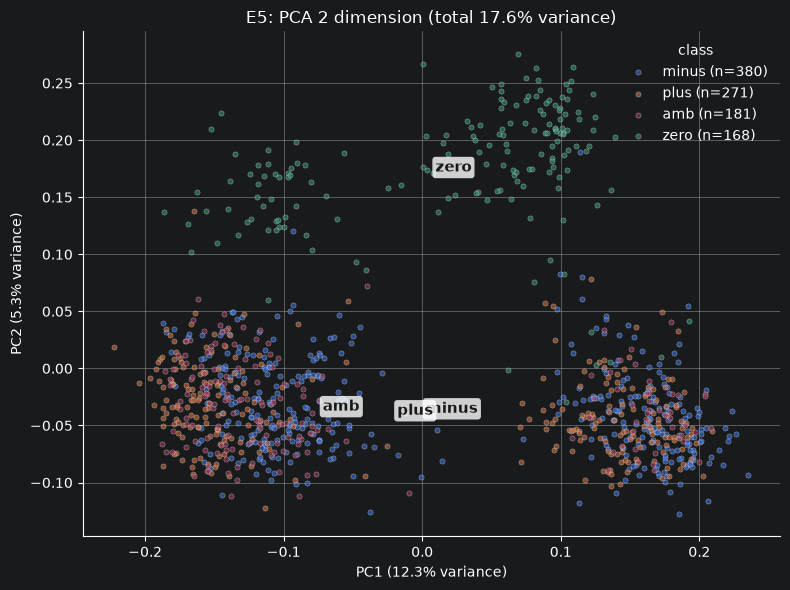

In [15]:
# Proszę zaimplementować PCA i przygotować wykres.
CLASS_ORDER = ["minus", "plus", "amb", "zero"]

pca =  PCA(n_components=2, random_state=RANDOM_STATE)

e5_2d = pca.fit_transform(emb_e5)
var = pca.explained_variance_ratio_
print(f"Explained variance: PC1 {var[0]:.1%}, PC2 {var[1]:.1%}, total {var.sum():.1%}")

fig, ax = plt.subplots(figsize=(8, 6))
for cls in CLASS_ORDER :
    mask = labels == cls
    ax.scatter(e5_2d[mask, 0], e5_2d[mask, 1], s=14, alpha=0.6, edgecolor="white", linewidth=0.3,
               label=f"{cls} (n={mask.sum()})")
    cx, cy = e5_2d[mask].mean(axis=0)
    ax.text(cx, cy, cls, fontsize=11, fontweight="bold", color="#1a1a19",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlabel(f"PC1 ({var[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} variance)")
ax.set_title(f"E5: PCA 2 dimension (total {var.sum():.1%} variance)")
ax.legend(title="class", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="lightgray", linewidth=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

- **Wariancja wyjaśniona:** dwie pierwsze składowe wyjaśniają tylko 17.6% wariancji (PC1 12.3%, PC2 5.3%), więc wykres pokazuje niewielki wycinek 384-wymiarowej przestrzeni.
- **`zero` jest wyraźnie oddzielona:** zajmuje górną część wykresu (wysokie PC2), prawie bez domieszki innych klas. To zgodne z tym, że ta klasa to głównie teksty prasowe i informacyjne, czyli inny gatunek niż recenzje.
- **`plus`, `minus` i `amb` mieszają się całkowicie:** tworzą dwa duże skupiska po obu stronach osi PC1 i w obu są wymieszane. Te skupiska nie odpowiadają sentymentowi, tylko najpewniej domenie tekstu (recenzje lekarzy kontra hoteli). Podobnie dzieli się nawet klasa `zero`, która też ma dwie podgrupy wzdłuż PC1. Środki ciężkości tych trzech klas leżą w pustej przestrzeni między skupiskami, bo każda klasa jest rozłożona na oba.
- **Wniosek:** główna oś zmienności E5 koduje temat, a nie wydźwięk. Na dwóch pierwszych składowych sentyment nie jest rozdzielony, choć purity@k (0.667 wobec 0.279 dla losowych sąsiadów) pokazuje, że jest częściowo zakodowany w dalszych wymiarach.

# Zadanie 8: Analiza przypadków

Proszę przygotować tabelę zawierającą dokładnie 12 przypadków, które pokazują ograniczenia reprezentacji wektorowych.

Pierwsze 6 przypadków należy znaleźć w wynikach najbliższych sąsiadów lub wyszukiwania. Powinny to być przykłady, w których podobieństwo jest wysokie, ale wynik jest problematyczny z punktu widzenia sentymentu lub intencji zapytania.

Kolejne 6 przypadków należy przygotować jako pary kontrastowe, np.:

```text
Hotel jest dobry.
Hotel nie jest dobry.
```

Dla każdej pary proszę policzyć podobieństwo w MiniLM i E5.

Tabela powinna zawierać:

| nr | typ | tekst A | tekst B / wynik | MiniLM | E5 | Δ MiniLM | Δ E5 | komentarz |
|---:|---|---|---|---:|---:|---:|---:|---|

Cosinusy E5 są skupione wysoko, więc nie wolno porównywać bezwzględnych wartości MiniLM i E5. Δ to różnica między cosinusem pary a cosinusem pary niezwiązanej tematycznie (np. "Hotel jest dobry." i "Samochód jest szybki.") liczonym tym samym modelem.

W komentarzu proszę używać krótkich kategorii, np.:

- negacja;
- wspólny temat;
- wspólne słownictwo;
- podobna forma;
- różny sentyment;
- bardzo krótki tekst;
- inna.


In [16]:
# Proszę znaleźć 6 przypadków z danych, przygotować 6 par kontrastowych i zbudować tabelę 12 przypadków.

def doc(i):
    return sample_df.loc[i, "text"]

cases = [
    # --- 6 przypadków z danych ---
    ("sąsiedzi E5: minus → plus", doc(620), doc(785), "symmetric",
     "wspólny temat; różny sentyment – oba o leczeniu migreny, jeden rozczarowany, drugi wdzięczny"),
    ("sąsiedzi E5: minus → plus", doc(207), doc(891), "symmetric",
     "wspólny temat; wspólne słownictwo – pierwsza wizyta u endokrynologa, przeciwna ocena"),
    ("sąsiedzi MiniLM: minus → plus", doc(21), doc(942), "symmetric",
     "wspólny temat; inna – negatyw wyrażony pośrednio („zmieniłam lekarza, najlepszy wybór”)"),
    ("sąsiedzi MiniLM: minus → plus", doc(294), doc(105), "symmetric",
     "wspólne słownictwo; podobna forma – „pani doktor miła”, ale w A to wstęp do krytyki"),
    ("wyszukiwanie E5: zapytanie minus → dokument plus",
     "Brudny pokój, nieprzyjemna obsługa, zdecydowanie odradzam ten hotel.", doc(365), "search",
     "wspólny temat; różny sentyment – na 1. miejscu pozytywna recenzja pokoju"),
    ("wyszukiwanie E5: zapytanie plus → dokument minus",
     "Wspaniały lekarz, bardzo polecam, profesjonalne i miłe podejście do pacjenta.", doc(61), "search",
     "wspólne słownictwo – „podejście do pacjenta” w recenzji negatywnej"),
    # --- 6 par kontrastowych ---
    ("para kontrastowa", "Hotel jest dobry.", "Hotel nie jest dobry.", "symmetric",
     "negacja – jedno słowo „nie” odwraca sentyment"),
    ("para kontrastowa", "Polecam ten hotel.", "Nie polecam tego hotelu.", "symmetric",
     "negacja – kluczowa fraza z Lab 2"),
    ("para kontrastowa", "Lekarz był bardzo miły i pomocny.", "Lekarz był bardzo niemiły i niepomocny.", "symmetric",
     "różny sentyment; wspólne słownictwo – przeciwieństwo przez przedrostek „nie-”"),
    ("para kontrastowa", "Pokój był czysty, ale obsługa fatalna.", "Pokój był brudny, ale obsługa wspaniała.", "symmetric",
     "podobna forma – ta sama budowa, zamienione oceny aspektów"),
    ("para kontrastowa", "Super!", "Fatalnie!", "symmetric",
     "bardzo krótki tekst – tylko jedno słowo oceniające"),
    ("para kontrastowa", "Pani doktor ma świetne podejście do pacjenta.",
     "Pani doktor ma podejście do pacjenta, jakiego nie życzę nikomu.", "symmetric",
     "inna (ironia) – wspólna fraza, negatyw wyrażony pośrednio"),
]

E5_PREFIXES = {"symmetric": ("query: ", "query: "), "search": ("query: ", "passage: ")}

def pair_cos(model, a, b, prefix_a="", prefix_b=""):
    emb = model.encode([prefix_a + a, prefix_b +b],normalize_embeddings=True)
    return float(emb[0] @ emb[1])


base_minilm = pair_cos(models["MiniLM"], "Hotel jest dobry.", "Samochód jest szybki.")
base_e5 = pair_cos(models["E5"], "Hotel jest dobry.", "Samochód jest szybki.", "query: ", "query: ")


rows = []

for nr, (t, a, b, mode, comment) in enumerate(cases, start=1):
    m = pair_cos(models["MiniLM"], a, b)
    e =  pair_cos(models["E5"], a, b, *E5_PREFIXES[mode])

    rows.append({
        "nr": nr,
        "typ": t,
        "tekst A": a[:120],
        "tekst B / wynik": b[:120],
        "MiniLM": m,
        "E5": e,
        "Δ MiniLM": m-base_minilm,
        "Δ E5": e-base_e5,
        "komentarz": comment,
    })

cases_df =  pd.DataFrame(rows).round(3)
print(f"Punkt odniesienia (Hotel jest dobry. / Samochód jest szybki.): MiniLM {base_minilm:.3f}, E5 {base_e5:.3f}")
cases_df


Punkt odniesienia (Hotel jest dobry. / Samochód jest szybki.): MiniLM 0.140, E5 0.834


,nr,typ,tekst A,tekst B / wynik,MiniLM,E5,Δ MiniLM,Δ E5,komentarz
0,1,sąsiedzi E5: minus → plus,"Niestety , bardzo chciała m wystawić dobrą opinię Pani doktor , ponieważ szła m do niej na pierwszą wizytę z wielką nadz",Ja do doktora Czapińskiego trafiła m 10 lat temu . Jestem mu wdzięczna za pomoc . Od bardzo dawna choruję na migrenę a d,0.800,0.945,0.660,0.111,"wspólny temat; różny sentyment – oba o leczeniu migreny, jeden rozczarowany, drugi wdzięczny"
1,2,sąsiedzi E5: minus → plus,"Była to moja pierwsza wizyta u endokrynologa . Po pozytywnych wpisach o Pani doktor była m pozytywnie nastawiona , ale o",Pani doktor anioł . . . ze świecą szukać w dzisiejszych czasach tak wspaniałych lekarzy . Przyszlam do pani dr z prośbą,0.721,0.940,0.581,0.106,"wspólny temat; wspólne słownictwo – pierwsza wizyta u endokrynologa, przeciwna ocena"
2,3,sąsiedzi MiniLM: minus → plus,"Pani doktor prowadziła moją ciążę prawie do końca . . . , gdyż po namowach i opiniach znajomych w ostatniej chwili zmien","Wspaniały lekarz . Pani doktor prowadziła moją pierwszą , bardzo wyczekaną ciążę . Podejście Pani doktor do pacjenta to",0.846,0.918,0.706,0.084,"wspólny temat; inna – negatyw wyrażony pośrednio („zmieniłam lekarza, najlepszy wybór”)"
3,4,sąsiedzi MiniLM: minus → plus,"Powiem szczerze , że nie rozumiem skąd ten zachwyt . Pani Monika rzeczywiście jest miła podczas wizyty , przyznaję , że","Z tą panią miała m do czynienie tylko raz - dodam dla ścisłości , że państwowo a nie prywatnie . Zastępowała mojego leka",0.849,0.914,0.709,0.080,"wspólne słownictwo; podobna forma – „pani doktor miła”, ale w A to wstęp do krytyki"
4,5,wyszukiwanie E5: zapytanie minus → dokument plus,"Brudny pokój, nieprzyjemna obsługa, zdecydowanie odradzam ten hotel.","Bardzo ładne pokoje , architekt sie napracował , choc wspolczuje Paniom sprzatajacym . Duzy komfort , jest ekskluzywnie",0.501,0.917,0.361,0.084,wspólny temat; różny sentyment – na 1. miejscu pozytywna recenzja pokoju
5,6,wyszukiwanie E5: zapytanie plus → dokument minus,"Wspaniały lekarz, bardzo polecam, profesjonalne i miłe podejście do pacjenta.","Pani doktor bardzo zmieniła podejście do pacjenta . Po kilku udanych wizytach w poprzednich latach , dwie ostatnie bardz",0.739,0.901,0.599,0.067,wspólne słownictwo – „podejście do pacjenta” w recenzji negatywnej
6,7,para kontrastowa,Hotel jest dobry.,Hotel nie jest dobry.,0.547,0.918,0.407,0.084,negacja – jedno słowo „nie” odwraca sentyment
7,8,para kontrastowa,Polecam ten hotel.,Nie polecam tego hotelu.,0.656,0.874,0.517,0.040,negacja – kluczowa fraza z Lab 2
8,9,para kontrastowa,Lekarz był bardzo miły i pomocny.,Lekarz był bardzo niemiły i niepomocny.,0.314,0.924,0.175,0.090,różny sentyment; wspólne słownictwo – przeciwieństwo przez przedrostek „nie-”
9,10,para kontrastowa,"Pokój był czysty, ale obsługa fatalna.","Pokój był brudny, ale obsługa wspaniała.",0.664,0.964,0.524,0.130,"podobna forma – ta sama budowa, zamienione oceny aspektów"


- **Przypadki z danych (1–6):** we wszystkich sześciu oba teksty mają ten sam temat (migrena, endokrynolog, ciąża, pokój hotelowy), ale przeciwny sentyment. E5 przypisuje im podobieństwo 0.90–0.95, a MiniLM 0.50–0.85, czyli zawsze wyraźnie więcej niż parze niezwiązanej tematycznie.
- **Pary kontrastowe (7–12):** w E5 każda para jest bardziej podobna niż para niezwiązana (Δ E5 od +0.036 do +0.130). Najwyższe podobieństwo w całej tabeli ma zamiana ocen aspektów (0.964), a negacja „Hotel jest dobry.” / „Hotel nie jest dobry.” ma 0.918. MiniLM trochę lepiej rozróżnia przeciwieństwa: najniżej ocenił „miły i pomocny” / „niemiły i niepomocny” (0.314, Δ +0.175), ale i u niego wszystkie pary są wysoko ponad punktem odniesienia (Δ MiniLM od +0.17 do +0.57).
- **Dominujące kategorie:** wspólny temat, negacja i podobna forma. Zmiana polaryzacji przesuwa wektor tylko nieznacznie, a o podobieństwie decyduje przede wszystkim to, o czym jest tekst i jak jest zbudowany.

# Zadanie 9: Interpretacja wyników

To zadanie nie wymaga nowej implementacji.

Na podstawie wyników zadań 1-8 proszę odpowiedzieć:

1. W jakich sytuacjach TF-IDF zachowywał się lepiej od reprezentacji gęstych?
2. W jakich sytuacjach przewagę miały MiniLM lub E5?
3. Czy wysoka wartość `purity@k` oznacza, że reprezentacja jest ogólnie "lepsza semantycznie"?
4. Czy model o najlepszym `Precision@10` musi być najlepszym wyborem do klasyfikacji sentymentu?
5. Jakie dwa ograniczenia eksperymentu najbardziej wpływają na interpretację wyników?

Odpowiedzi powinny odwoływać się do uzyskanych liczb i przykładów.

**1. W jakich sytuacjach TF-IDF zachowywał się lepiej od reprezentacji gęstych?**

- **Koszt:** TF-IDF jest najtańszy: ok. 0.20 ms/dokument wobec ok. 1.6 ms dla MiniLM (ok. 8×) i ok. 3.7 ms dla E5 (ok. 19×), mimo że gęste modele liczono na GPU (MPS).
- **Pełny tekst:** TF-IDF zawsze widzi cały tekst, a MiniLM obcina 76.9% recenzji do 128 tokenów.
- **Wyszukiwanie:** TF-IDF nie był gorszy. Precision@5 wyniosło 0.600 (tyle samo co MiniLM, więcej niż E5 z 0.575), a dla zapytań `zero` miał najwyższe P@10 (0.40). Zapytania mają konkretne słowa („odradzam”, „hotel”, „szpitali”), które po prostu występują w dokumentach.
- **Różnice w ocenie:** z definicji TF-IDF nie uzna za podobne zdań bez wspólnych słów („Super!” / „Fatalnie!”), a gęste modele przypisują takim parom wysokie podobieństwo.

**2. W jakich sytuacjach przewagę miały MiniLM lub E5?**

- **Parafrazy:** w Zadaniu 2 oba modele wskazały A–B jako najbardziej podobne. TF-IDF dał tej parze 0 i wybrał A–C, czyli zdania o przeciwnym sentymencie, które łączą wspólne słowa.
- **Sąsiedztwo:** E5 ma najwyższą purity dla każdego k (0.694 / 0.667 / 0.642 wobec 0.582 / 0.555 / 0.534 dla TF-IDF) i jest najlepszy w każdej klasie. Najbardziej widać to w `plus` (0.661 vs 0.486) i `amb` (0.348 vs 0.240). MiniLM wypada pośrodku.
- **Długie teksty:** E5 ma okno 512 tokenów i obcina tylko 4.1% tekstów.

**3. Czy wysoka `purity@k` oznacza, że reprezentacja jest ogólnie „lepsza semantycznie”?**

Nie. Purity mierzy tylko jedną rzecz: czy sąsiedzi mają tę samą **etykietę sentymentu**. Część wyniku to efekt gatunku tekstu: `zero` ma najwyższą purity (0.829 w E5), bo teksty prasowe tworzą osobny klaster (PCA). Sąsiedztwo układa się przede wszystkim według tematu: w Zadaniu 4 wszyscy sąsiedzi mieli tę samą domenę, a PC1 rozdziela hotele i lekarzy. Najlepszy model nie rozróżnia też podstawowych zmian znaczenia: w E5 „Hotel jest dobry.” / „Hotel nie jest dobry.” ma podobieństwo 0.918, a więc **wyżej** niż losowa para niezwiązanych zdań (Δ +0.084). Dla `amb` purity@5 w E5 to tylko 0.348.

**4. Czy model o najlepszym `Precision@10` musi być najlepszym wyborem do klasyfikacji sentymentu?**

Nie. Najlepsze P@10 ma MiniLM (0.550), ale przewaga nad TF-IDF (0.525) i E5 (0.512) jest mniejsza niż 0.1, więc przy 8 zapytaniach to szum. Jednocześnie w purity wyraźnie wygrywa E5 (0.667 vs 0.587 dla MiniLM). Wyszukiwanie top-10 dla krótkiego zapytania sprawdza co innego niż rozdzielność klas w całej przestrzeni. Wybór do klasyfikacji wymaga wytrenowania klasyfikatora na embeddingach i porównania macro-F1 z baseline'em z Lab 2 (TF-IDF + LogReg: 0.80 na teście).

**5. Jakie dwa ograniczenia eksperymentu najbardziej wpływają na interpretację wyników?**

1. **Miniaturowy benchmark z przybliżoną relewancją:** 8 zapytań napisanych ręcznie, a relewancję zastępuje etykieta sentymentu. Precision@5 pojedynczych zapytań waha się od 0.0 (zapytanie `amb` w MiniLM) do 1.0 (zapytania `minus`), więc średnie P@k zależą głównie od doboru zapytań, a różnice poniżej 0.1 są nieinterpretowalne.
2. **Obcinanie tekstu przez okno modelu:** MiniLM widzi pełny tekst tylko w 23% recenzji (76.9% obciętych), a E5 w 96%. Porównanie MiniLM z E5 jest więc częściowo porównaniem ilości przeczytanego tekstu, a nie samej jakości reprezentacji. W recenzjach werdykt często pada na końcu.

# Zadanie 10: Decyzja projektowa

To zadanie nie wymaga nowej implementacji.

Proszę wybrać reprezentację dla każdego z trzech zastosowań:

1. szybkie wyszukiwanie po dokładnych nazwach i terminach;
2. wyszukiwanie semantyczne parafraz;
3. przyszły system RAG.

Dla każdego zastosowania proszę podać:

- wybraną reprezentację;
- jeden wynik ilościowy (jakość lub koszt) uzasadniający decyzję;
- jeden obserwowany przypadek błędu lub ograniczenie;
- koszt, który należy zaakceptować.

Na końcu proszę odpowiedzieć jednym akapitem na pytanie:

**Dlaczego embeddingu nie należy utożsamiać ze "znaczeniem tekstu"?**

**1. Szybkie wyszukiwanie po dokładnych nazwach i terminach → TF-IDF**

- **Wynik ilościowy:** najtańsza reprezentacja: ok. 0.2 ms/dokument, czyli ok. 8× szybciej niż MiniLM i ok. 19× szybciej niż E5. Działa na CPU, bez modelu i bez GPU. Dokument pasuje, jeśli zawiera dokładnie to słowo lub n-gram z zapytania, a TF-IDF zawsze widzi cały tekst, bez obcinania.
- **Ograniczenie:** TF-IDF porównuje słowa, a nie sens. W Zadaniu 1 zdania „Hotel był bardzo dobry.” i „Hotel był bardzo zły.” dostały podobieństwo 0.63, bo mają wspólne słowa, a parafraza „Obiekt noclegowy zrobił na mnie świetne wrażenie.” dostała 0.
- **Koszt do zaakceptowania:** brak obsługi synonimów i odmiany. „hotel” i „hotelu” to różne cechy, więc odmienione formy i literówki nie zostaną znalezione. Słownik rośnie razem z korpusem (już na 1000 dokumentach ma 15 633 cechy) i trzeba go dopasować ponownie, gdy pojawiają się nowe nazwy.

**2. Wyszukiwanie semantyczne parafraz → MiniLM**

- **Wynik ilościowy:** w Zadaniu 2 MiniLM, podobnie jak E5, uznał parafrazę A–B za najbardziej podobną parę, a TF-IDF dał jej 0. MiniLM ma przy tym szeroką skalę podobieństw: para niezwiązana to 0.14, a większość par tematycznych 0.7–0.85. Łatwiej więc ustawić próg „to jest parafraza” niż w E5, gdzie nawet niezwiązane zdania mają 0.83. Model był trenowany właśnie na parafrazach (`paraphrase-multilingual`).
- **Ograniczenie:** okno 128 tokenów obcina 76.9% recenzji, więc MiniLM nadaje się do parafraz krótkich tekstów (zdań, zapytań), a nie całych dokumentów. Nie rozróżnia też negacji: „Hotel jest dobry.” / „Hotel nie jest dobry.” ma podobieństwo 0.547, czyli wysoko ponad punktem odniesienia (Δ +0.41).
- **Koszt do zaakceptowania:** ok. 1.6 ms/dokument (ok. 8× wolniej niż TF-IDF), pobranie i przechowywanie modelu oraz GPU dla dużych zbiorów. Embeddingi mają stały rozmiar 384 × float32, czyli ok. 1.5 KB na dokument.

**3. Przyszły system RAG → E5**

- **Wynik ilościowy:** najlepsza jakość sąsiedztwa (purity@5 0.667 wobec 0.587 dla MiniLM i 0.555 dla TF-IDF) i okno 512 tokenów, które obcina tylko 4.1% recenzji. Dzięki temu model widzi prawie całe dokumenty, które RAG ma potem przekazać do LLM-a. Model ma też osobne prefiksy `query:` i `passage:`, zaprojektowane do wyszukiwania krótkie zapytanie → długi dokument.
- **Ograniczenie:** cosinusy są skupione wysoko. Niezwiązana para ma 0.834, a negacja „Hotel jest dobry.” / „Hotel nie jest dobry.” 0.918, więc nie da się ustawić sensownego stałego progu podobieństwa. W naszym benchmarku E5 nie wygrał wyszukiwania (P@5 0.575 wobec 0.600 dla TF-IDF), a dla zapytań `amb` P@10 wyniosło tylko 0.25.
- **Koszt do zaakceptowania:** najwolniejszy model (ok. 3.7 ms/dokument, ok. 19× wolniej niż TF-IDF), konieczność kodowania dokumentów osobno z prefiksem `passage:` i pilnowania prefiksów w całym systemie. W praktyce warto połączyć go z TF-IDF/BM25 (wyszukiwanie hybrydowe), żeby nie tracić trafień po dokładnych nazwach.

**Dlaczego embeddingu nie należy utożsamiać ze „znaczeniem tekstu”?**

Embedding to wynik modelu trenowanego do konkretnego celu (parafrazy, wyszukiwania), a jego podobieństwo mierzy to, czego model nauczył się w tym celu, a nie pełne znaczenie. W naszych wynikach embeddingi grupowały teksty przede wszystkim według tematu: PC1 rozdziela hotele i lekarzy, a sąsiedzi z Zadania 4 zawsze mieli tę samą domenę. Recenzje o przeciwnym sentymencie dostawały przy tym bardzo wysokie podobieństwo (np. 0.945 w E5 dla dwóch recenzji o leczeniu migreny: rozczarowanej i wdzięcznej). Negacja, która odwraca sens zdania, zmienia podobieństwo tylko nieznacznie („Hotel jest dobry.” / „Hotel nie jest dobry.”: 0.918 w E5). Do tego model widzi tylko tekst mieszczący się w oknie (MiniLM obcina 76.9% recenzji), a wartości cosinusa nie są porównywalne między modelami (para niezwiązana: 0.14 w MiniLM, 0.83 w E5). Embedding jest więc użytecznym, ale stratnym i zależnym od modelu przybliżeniem pewnych aspektów tekstu, a nie jego znaczeniem.

# Karta modelu embeddingowego

Proszę wybrać jeden z dwóch modeli gęstej reprezentacji jako model rekomendowany do dalszych laboratoriów i utworzyć:

```text
artifacts/embedding_model_card.md
```

Karta powinna zawierać:

## Model
- nazwa checkpointu;
- wymiar reprezentacji;
- sposób normalizacji;
- wymagane prefiksy wejścia, jeśli dotyczy.

## Dane
- użyty zbiór;
- wielkość próbki;
- odsetek tekstów obciętych przez okno modelu;
- sposób doboru próbki.

## Koszt
- czas utworzenia reprezentacji;
- ms/dokument;
- rozmiar reprezentacji w pamięci.

## Jakość sąsiedztwa
- `purity@1`;
- `purity@5`;
- `purity@10`.

## Wyszukiwanie
- `Precision@5`;
- `Precision@10`.

## Analiza jakościowa
- najważniejsze obserwacje z PCA;
- dominujące typy błędów z analizy 20 przypadków.

## Zastosowanie
- do jakich zadań model jest rekomendowany;
- do jakich zadań nie należy go wybierać wyłącznie na podstawie tego laboratorium.

## Ograniczenia
- ograniczenia danych;
- ograniczenia benchmarku;
- ograniczenia samej reprezentacji.


Karta została zapisana w pliku [`artifacts/embedding_model_card.md`](../artifacts/embedding_model_card.md). Jako model rekomendowany do dalszych laboratoriów wybrano **E5** (`intfloat/multilingual-e5-small`): ma najwyższą purity@k we wszystkich klasach, obcina tylko 4.1% tekstów (okno 512 tokenów) i ma prefiksy `query:` / `passage:` przeznaczone do wyszukiwania, czyli do przyszłego systemu RAG.

# Wnioski

Na koniec pracy proszę zapisać krótkie wnioski. Każdy wniosek powinien wynikać z wykonanego eksperymentu i zawierać odwołanie do wyniku liczbowego, obserwacji albo konkretnego przypadku.

Nie należy przepisywać definicji TF-IDF, embeddingów ani podobieństwa cosinusowego.

1. **Gęste reprezentacje rozpoznają parafrazy, których TF-IDF nie widzi, ale E5 robi to z minimalnym marginesem.** Dla zdań z Zadania 1 TF-IDF dał parafrazie A–B podobieństwo 0, a zdaniom o przeciwnym sentymencie A–C 0.634. MiniLM odwrócił tę kolejność wyraźnie (A–B 0.749 vs A–C 0.378), a E5 tylko nieznacznie (0.927 vs 0.909).

2. **Sąsiedztwo w przestrzeni embeddingów układa się według tematu, a nie sentymentu.** W Zadaniu 4 wszyscy sąsiedzi każdego dokumentu pochodzili z tej samej domeny (hotel z hotelem, lekarz z lekarzem), ale dla dokumentu `amb` tylko 0–1 z 5 sąsiadów miało tę samą etykietę. PCA potwierdza to samo: PC1 rozdziela dwie domeny, w których `plus`, `minus` i `amb` są wymieszane, a osobno leży tylko `zero` (teksty prasowe).

3. **Wszystkie reprezentacje niosą informację o sentymencie, ale ambiwalencję kodują słabo.** purity@5 wynosi 0.667 dla E5, 0.587 dla MiniLM i 0.555 dla TF-IDF, czyli wyraźnie powyżej losowego punktu odniesienia 0.279. Dla `amb` najlepszy wynik (E5: 0.348) jest jednak tylko o ok. 0.17 wyższy od udziału tej klasy w próbce (0.181).

4. **Benchmark wyszukiwania nie wskazuje zwycięzcy, a wynik zależy bardziej od klasy zapytania niż od reprezentacji.** Średnie Precision@5 mieszczą się w 0.575–0.600, a Precision@10 w 0.512–0.550, więc różnice są poniżej progu 0.1. Zapytania `minus` osiągają P@10 0.70–0.90, a zapytania `amb` tylko 0.20–0.25 we wszystkich trzech reprezentacjach.

5. **Ani MiniLM, ani E5 nie rozróżniają negacji i zamiany ocen.** W E5 „Hotel jest dobry.” / „Hotel nie jest dobry.” ma podobieństwo 0.918, czyli więcej niż para niezwiązana tematycznie (0.834), a zamiana ocen aspektów („Pokój czysty, ale obsługa fatalna” / „Pokój brudny, ale obsługa wspaniała”) dostała najwyższe podobieństwo w całej tabeli: 0.964. W MiniLM nawet „Super!” / „Fatalnie!” ma 0.614 (Δ +0.47).

6. **Wartości cosinusa nie są porównywalne między modelami.** Para niezwiązana tematycznie ma 0.140 w MiniLM i 0.834 w E5, a Δ E5 dla wszystkich 12 przypadków z Zadania 8 mieści się w wąskim zakresie 0.04–0.13. Modele trzeba porównywać przez kolejność wyników albo Δ, a stały próg podobieństwa w E5 nie ma sensu.

7. **Okno modelu i koszt są realnym kryterium wyboru.** MiniLM obcina 76.9% recenzji do 128 tokenów, a E5 tylko 4.1% (okno 512). Za dłuższe okno E5 płaci kosztem: ok. 3.7 ms/dokument, czyli ok. 2.4× więcej niż MiniLM (ok. 1.6 ms) i ok. 19× więcej niż TF-IDF (ok. 0.2 ms). Dlatego E5 rekomendujemy do RAG, najlepiej w połączeniu z TF-IDF/BM25 dla dokładnych nazw.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] własną implementację eksperymentu TF-IDF i podobieństwa cosinusowego;
- [ ] reprezentacje MiniLM i E5;
- [ ] deterministyczną próbkę danych;
- [ ] benchmark czasu i pamięci trzech reprezentacji;
- [ ] implementację wyszukiwania najbliższych sąsiadów;
- [ ] `purity@1`, `purity@5`, `purity@10`;
- [ ] osiem zapytań w benchmarku wyszukiwania;
- [ ] własną implementację `Precision@k`;
- [ ] `Precision@5` i `Precision@10`;
- [ ] wizualizację PCA;
- [ ] tabelę 12 przypadków błędów i par kontrastowych;
- [ ] sprawdzenie okna modeli (`max_seq_length`) i odsetka obciętych tekstów;
- [ ] purity z punktem odniesienia (losowi sąsiedzi) i per klasa;
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 9);
- [ ] plik `artifacts/embedding_model_card.md`;
- [ ] od pięciu do ośmiu wniosków końcowych.